# Portfolio Risk Analyzer

a Python tool that pulls Market data for a multiasset portfolio and compute core risk and performance metrics: Annualised return, volatility, Sharpe ration and maximum drawdown, with supporting viosualisations.

**Data:** Daily prices via 'yfinance' (Yahoo Finance) Oct 2023 - Oct 2025.
**Note:** Returns are computed in each asset's local currrency without FX conversion.

## 1. Setup

Load the libraries: 'pandas'/'numpy' for data, 'yfinance' for prices, 'matplotlib/seaborn' for charts.

In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

Environment is working


## 2. Data

Pull daily closing prices for six holdins.

In [65]:
tickers = ["VTI", "QQQ", "NOK", "QTUM", "MU", "CSP1.L"]
data = yf.download(tickers, start="2023-10-01", end="2025-10-01")
prices = data["Close"]

[*********************100%***********************]  6 of 6 completed


## 3. Returns

Convert prices to daily returns with 'pct_change()', so we can have the assets on a comparable percentage scale.

Defining the weight for each asset, used to compute weighted average portfolio return. 

In [66]:
returns = prices.pct_change()
returns = returns.dropna()
returns.head()

Ticker,CSP1.L,MU,NOK,QQQ,QTUM,VTI
Date,,,,,,
2023-10-03,-0.010329,-0.001913,-0.013441,-0.017550,-0.016910,-0.014519
2023-10-04,-0.002240,0.004128,-0.013624,0.013609,0.005946,0.007223
2023-10-05,-0.003834,0.013801,-0.022099,-0.002946,-0.002322,-0.000522
2023-10-06,0.004701,0.014869,0.005650,0.016755,0.019255,0.011927
2023-10-09,0.007688,-0.006861,0.000000,0.005100,-0.002076,0.006292


In [67]:
weights = {
    "CSP1.L": 0.10,
    "MU":     0.10,
    "NOK":    0.10,
    "QQQ":    0.25,
    "QTUM":   0.15,
    "VTI":    0.30,  
}

In [68]:
weights_series = pd.Series(weights)

In [69]:
portfolio_returns = (returns * weights_series).sum(axis=1)
portfolio_returns.head()

Date
2023-10-03   -0.013848
2023-10-04    0.005287
2023-10-05   -0.002455
2023-10-06    0.013177
2023-10-09    0.002934
dtype: float64

# 4. Annualised Returns and Risk Metrics

Computing the annualised return, assuming 252 trading days per year.

Three risk metrics are then derived:
- **Annualised volatility** — the standard deviation of returns (scaled by √252), a measure of how much returns fluctuate: the standard proxy for risk.
- **Sharpe ratio** — return earned per unit of risk (risk-free rate assumed 0 for this version).
- **Maximum drawdown** — the largest peak-to-trough fall, i.e. the worst loss an investor would have endured.

In [76]:
# Trading days in a year
Trading_days = 252

# Annualized returns, average daily return multiplied by the number of trading days in a year
annualized_returns = portfolio_returns.mean() * Trading_days

# Annualized volatility, standard deviation of daily returns multiplied by the square root of the number of trading days in a year
annualized_volatility = portfolio_returns.std() * np.sqrt(Trading_days)

# sharpe ratio, annualized returns divided by annualized volatility
sharpe_ratio = annualized_returns / annualized_volatility

print(f"Annualised return: {annualized_returns:.2%}")
print(f"Annualised volatility: {annualized_volatility:.2%}")
print(f"Sharpe ratio: {sharpe_ratio:.2f}")

Annualised return: 35.84%
Annualised volatility: 19.64%
Sharpe ratio: 1.82


36% annualised at ~20% vol — strong, but driven by a tech-heavy tilt in a favourable window.

In [77]:
cumulative = (1 + portfolio_returns).cumprod()
running_max = cumulative.cummax()
drawdown = (cumulative - running_max) / running_max
max_drawdown = drawdown.min()
print(f"Maximum drawdown: {max_drawdown:.2%}")

trough_date = drawdown.idxmin()
peak_date = cumulative[:trough_date].idxmax()

Maximum drawdown: -21.38%


Expected Drawdown due heavy tech holding.

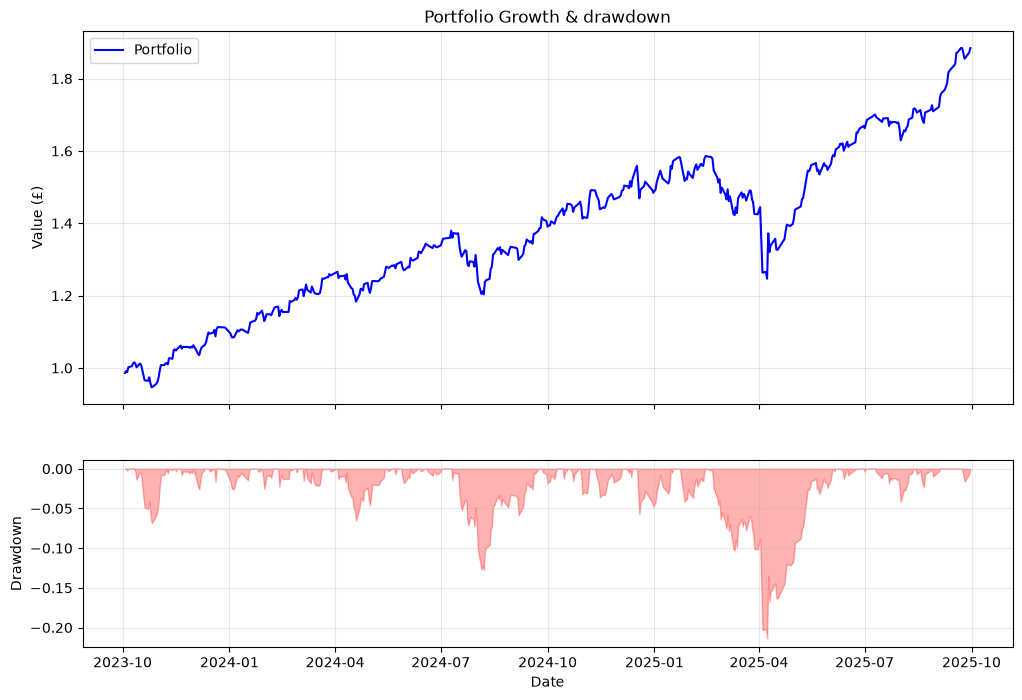

In [78]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                                gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(cumulative, label="Portfolio", color='blue')
ax1.set_title("Portfolio Growth & drawdown")
ax1.set_ylabel("Value (£)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.fill_between(drawdown.index, drawdown, color='red', alpha=0.3)
ax2.set_ylabel("Drawdown")
ax2.set_xlabel("Date")
ax2.grid(True, alpha=0.3)

In [79]:
corr = returns.corr()

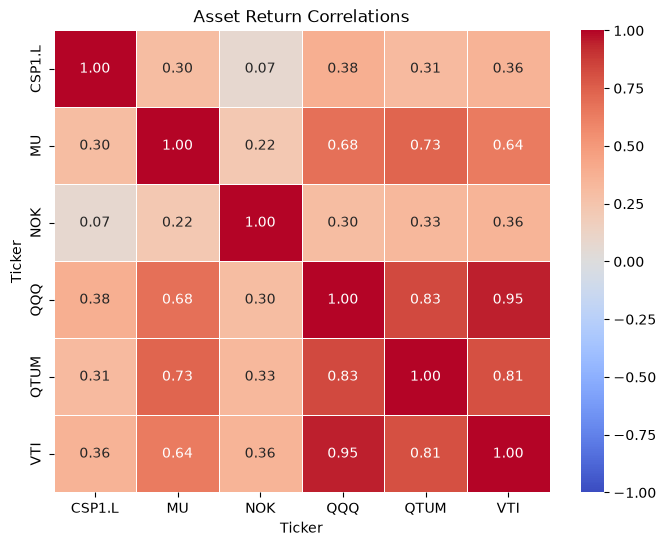

In [80]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, 
                annot=True, 
                cmap='coolwarm',
                vmin=-1, 
                vmax=1,
                center=0, 
                fmt=".2f", 
                linewidths=0.5)
plt.title("Asset Return Correlations")
plt.show()

The six holdings show relatively high correlations, driven by heavy overlap in their underlying exposure — QQQ, VTI, QTUM and MU are all tech/semiconductor-concentrated, so they effectively represent a single large US-tech bet rather than four independent positions. Genuine diversification comes from only two sources: NOK (Nokia, a Finnish telecom name uncorrelated with the tech bloc) and CSP1.L, whose GBP denomination partly decouples its returns from the USD-priced holdings via the exchange-rate effect.

## Limitations & Next Steps

- **Sharpe assumes a 0% risk-free rate** — the real figure would be modestly lower.
- **No FX conversion** — US assets are in USD, CSP1.L in GBP; a true sterling-
  investor view would adjust for GBP/USD moves.
- **Short window** — two favourable years flatter returns; not forward-looking.
- **Next:** add FX adjustment, a real risk-free rate, and rolling volatility.